In [1]:
# Project path setup: works whether Jupyter was launched from the project root or notebooks/.
from pathlib import Path
import os
cwd = Path.cwd()
if (cwd / "data").is_dir() and (cwd / "notebooks").is_dir():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data").is_dir() and cwd.name == "notebooks":
    PROJECT_ROOT = cwd.parent
else:
    raise RuntimeError("Open this notebook from the project root or its notebooks/ folder.")
os.chdir(PROJECT_ROOT / "notebooks")
print("Project root:", PROJECT_ROOT)
print("Notebook working directory:", Path.cwd())

Project root: /home/akshat/Desktop/main files (i think)/ml course work/ml project
Notebook working directory: /home/akshat/Desktop/main files (i think)/ml course work/ml project/notebooks


# 08 — Final Evaluation of Logistic Regression

## Objective

Fit the final selected Logistic Regression pipeline on the complete training split and evaluate it on the existing held-out test split. The hyperparameters are imported from `src/train.py` to keep the notebook and command-line workflow consistent.

**Final model:** TF-IDF unigrams + bigrams (`min_df=10`, `max_df=1.0`, `max_features=100000`, `sublinear_tf=True`) + Logistic Regression with L2 regularisation (`C=3`, `solver="liblinear"`).

**Evaluation caveat:** the test split was inspected during earlier development. Report these as the project’s existing held-out split results, not as a pristine independent external validation. Do not use the test metrics for further tuning.

In [2]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, roc_auc_score, classification_report,
    confusion_matrix, roc_curve
)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from train import build_pipeline, CV_MACRO_F1

sns.set_theme(style="whitegrid")

In [3]:
train_df = pd.read_csv("../data/processed/train.csv")
test_df = pd.read_csv("../data/processed/test.csv")

X_train = train_df["text"]
y_train = train_df["target"]

X_test = test_df["text"]
y_test = test_df["target"]

print("Training dataset shape:", X_train.shape)
print("Test dataset shape:", X_test.shape)

print("\nTraining label distribution:")
print(y_train.value_counts().sort_index())

print("\nTest label distribution:")
print(y_test.value_counts().sort_index())

Training dataset shape: (32328,)
Test dataset shape: (8082,)

Training label distribution:
target
0    16172
1    16156
Name: count, dtype: int64

Test label distribution:
target
0    4043
1    4039
Name: count, dtype: int64


## Final Model

The selected pipeline is loaded from the model-improvement notebook. That notebook selects a candidate using stratified cross-validation on the training data.

The pipeline is then fitted on the full training split and evaluated on the held-out test split. Note that this test set has been inspected in earlier project work, so the result should not be described as a completely untouched final evaluation.


In [4]:
# Build and fit the shared final Logistic Regression configuration.
final_model = build_pipeline()
final_model.fit(X_train, y_train)
print("Final model: Logistic Regression (L2 / Ridge)")
print(f"Recorded cross-validation Macro F1: {CV_MACRO_F1:.4%}")
print("Pipeline:", final_model)

Final model: Logistic Regression (L2 / Ridge)
Recorded cross-validation Macro F1: 93.9769%
Pipeline: Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=100000, min_df=10,
                                 ngram_range=(1, 2), sublinear_tf=True)),
                ('classifier',
                 LogisticRegression(C=3.0, max_iter=5000, random_state=42,
                                    solver='liblinear'))])


In [5]:
final_model.fit(X_train, y_train)

print("Final model trained successfully.")

Final model trained successfully.


In [6]:
y_pred = final_model.predict(X_test)
y_scores = final_model.predict_proba(X_test)[:, 1]

assert len(y_pred) == len(y_test)
print("Test predictions and positive-class probabilities generated.")

Test predictions and positive-class probabilities generated.


## Evaluation Metrics

We evaluate the model using the following metrics:

- Accuracy: Overall proportion of correct predictions.
- Precision: Proportion of predicted positive (CG) reviews that are actually CG.
- Recall: Proportion of actual CG reviews correctly identified.
- F1-score: Harmonic mean of precision and recall.
- Macro F1-score: Average F1-score across both classes, treating them equally.
- Balanced Accuracy: Average recall across both classes.
- ROC-AUC: Measures how well the model separates the two classes across different decision thresholds.

In [7]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, pos_label=1)
recall = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)

macro_f1 = f1_score(y_test, y_pred, average="macro")
balanced_acc = balanced_accuracy_score(y_test, y_pred)

roc_auc = roc_auc_score(y_test, y_scores)

test_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision (CG)",
        "Recall (CG)",
        "F1-score (CG)",
        "Macro F1-score",
        "Balanced Accuracy",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        macro_f1,
        balanced_acc,
        roc_auc
    ]
})

test_metrics["Score"] = test_metrics["Score"].round(4)

test_metrics

,Metric,Score
0,Accuracy,0.9448
1,Precision (CG),0.9538
2,Recall (CG),0.9349
3,F1-score (CG),0.9442
4,Macro F1-score,0.9448
5,Balanced Accuracy,0.9448
6,ROC-AUC,0.9871


In [8]:
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["OR", "CG"],
        digits=4
    )
)

              precision    recall  f1-score   support

          OR     0.9362    0.9547    0.9454      4043
          CG     0.9538    0.9349    0.9442      4039

    accuracy                         0.9448      8082
   macro avg     0.9450    0.9448    0.9448      8082
weighted avg     0.9450    0.9448    0.9448      8082



## Confusion Matrix

A confusion matrix compares the actual labels with the model's predicted labels.

It helps us identify:
- True Negatives (TN): OR reviews correctly predicted as OR.
- False Positives (FP): OR reviews incorrectly predicted as CG.
- False Negatives (FN): CG reviews incorrectly predicted as OR.
- True Positives (TP): CG reviews correctly predicted as CG.

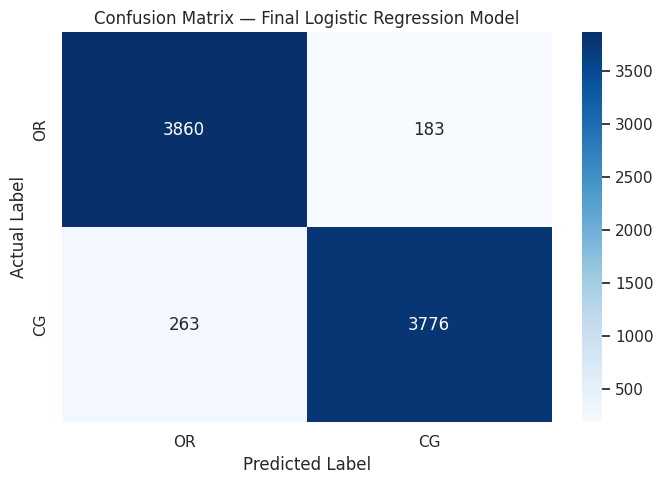

In [9]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["OR", "CG"], yticklabels=["OR", "CG"])
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix — Final Logistic Regression Model")
plt.tight_layout()
plt.savefig("../results/figures/final_confusion_matrix_logistic_regression.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
tn, fp, fn, tp = cm.ravel()

print("True Negatives (OR correctly classified):", tn)
print("False Positives (OR incorrectly classified as CG):", fp)
print("False Negatives (CG incorrectly classified as OR):", fn)
print("True Positives (CG correctly classified):", tp)

print("\nTotal incorrect predictions:", fp + fn)

True Negatives (OR correctly classified): 3860
False Positives (OR incorrectly classified as CG): 183
False Negatives (CG incorrectly classified as OR): 263
True Positives (CG correctly classified): 3776

Total incorrect predictions: 446


In [11]:
total_test_errors = fp + fn

print("\nTotal test reviews:", len(y_test))
print("Correct predictions:", len(y_test) - total_test_errors)
print("Incorrect predictions:", total_test_errors)

print(
    "Test error rate:",
    f"{total_test_errors / len(y_test):.2%}"
)


Total test reviews: 8082
Correct predictions: 7636
Incorrect predictions: 446
Test error rate: 5.52%


## ROC Curve

The Receiver Operating Characteristic (ROC) curve illustrates the trade-off between:

- True Positive Rate (TPR): Proportion of actual CG reviews correctly identified.
- False Positive Rate (FPR): Proportion of actual OR reviews incorrectly classified as CG.

The Area Under the Curve (AUC) summarizes the model's ability to distinguish between the two classes. A higher AUC indicates better class separation.

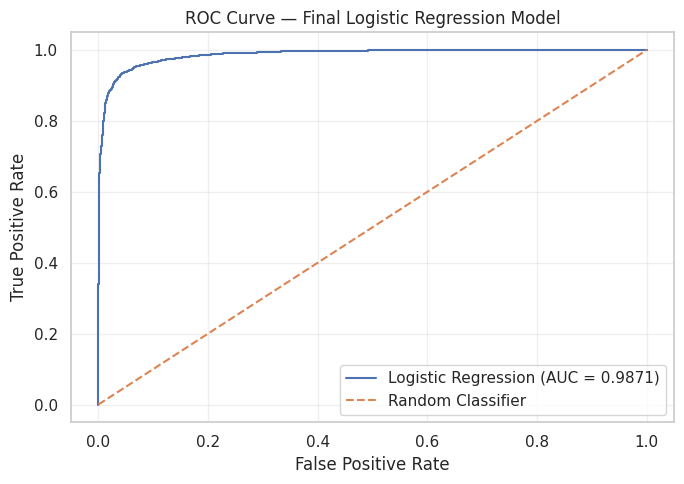

In [12]:
fpr, tpr, thresholds = roc_curve(y_test, y_scores)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Final Logistic Regression Model")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../results/figures/final_roc_curve_logistic_regression.png", dpi=300, bbox_inches="tight")
plt.show()

## Cross-Validation vs Test Performance

We compare the selected model's cross-validation Macro F1 with its held-out test Macro F1.

This is a descriptive comparison, not an entirely independent estimate of generalisation, because the test set was inspected in earlier project work. The test set should not be used for further hyperparameter selection.


In [13]:
comparison = pd.DataFrame({
    "Metric": ["Macro F1"],
    "Cross-Validation": [CV_MACRO_F1],
    "Test": [macro_f1]
})
comparison["Difference"] = comparison["Test"] - comparison["Cross-Validation"]
comparison.round(4)

,Metric,Cross-Validation,Test,Difference
0,Macro F1,0.9398,0.9448,0.005


In [14]:
RESULT_DIR = Path("../results/final_logistic_regression")
METRICS_DIR = RESULT_DIR / "metrics"
PREDICTIONS_DIR = RESULT_DIR / "predictions"
MODEL_DIR = Path("../models/final")
for directory in (METRICS_DIR, PREDICTIONS_DIR, MODEL_DIR):
    directory.mkdir(parents=True, exist_ok=True)

test_metrics.to_csv(METRICS_DIR / "final_test_metrics.csv", index=False)
comparison.to_csv(RESULT_DIR / "cv_vs_test_comparison.csv", index=False)
print("Evaluation metrics saved successfully.")

Evaluation metrics saved successfully.


In [15]:
test_predictions = pd.DataFrame({
    "text": X_test,
    "actual": y_test,
    "predicted": y_pred,
    "probability_cg": y_scores,
    "correct": y_test.to_numpy() == y_pred
})
test_predictions.to_csv(PREDICTIONS_DIR / "final_test_predictions.csv", index=False)
joblib.dump(final_model, MODEL_DIR / "final_logistic_regression_pipeline.joblib")
print("Saved test predictions and final model.")
print("Number of predictions:", len(test_predictions))

Saved test predictions and final model.
Number of predictions: 8082


The fitted Logistic Regression pipeline and evaluation outputs were saved in the previous cell under `models/final/` and `results/final_logistic_regression/`.